In [6]:
import numpy as np
import matplotlib.pyplot as plt
import function as fn

# 1. Configuração dos arquivos

INPUT_FILE = "foto1.jpeg"
OUTPUT_GRAY_FILE = "foto1Cinza.png"


In [7]:

# 2. Conversão RGB para YCrCb

matrizBase = np.array([
    [ 0.299000,  0.587000,  0.114000],
    [ 0.500000, -0.418688, -0.081312],
    [-0.168736, -0.331264,  0.500000]
], dtype=np.float64)

deslocamento = np.array([0, 128, 128], dtype=np.float64)

ycrcb = fn.rgb_to_ycrcb(
    INPUT_FILE,
    OUTPUT_GRAY_FILE,
    matrizBase,
    deslocamento
)

# 3. Aplicação da DCT 2D

F_blocos, blocos, Y, numBlocosAltura, numBlocosLargura, altura, largura = (
    fn.apply_dct(ycrcb, 8)
)

print("\nDimensões dos blocos transformados:", F_blocos.shape)

# 4. Matriz de quantização

Q = np.array([
    [16, 11, 10, 16, 24, 40, 51, 61],
    [12, 12, 14, 19, 26, 58, 60, 55],
    [14, 13, 16, 24, 40, 57, 69, 56],
    [14, 17, 22, 29, 51, 87, 80, 62],
    [18, 22, 37, 56, 68, 109, 103, 77],
    [24, 35, 55, 64, 81, 104, 113, 92],
    [49, 64, 78, 87, 103, 121, 120, 101],
    [72, 92, 95, 98, 112, 100, 103, 99]
], dtype=np.float64)

print("\nMatriz de quantização (Q):")
print(Q)


Dimensões da imagem: (1104, 736, 3)
Tipo dos dados: float64
Primeiro pixel de YCrCb: [ 90.958     65.975744 143.260736]
primeiro pixel da imagem deslocada: -37.042
Dimensões originais: (1104, 736)
Linhas a adicionar: 0
Colunas a adicionar: 0
Dimensões após o padding: (1104, 736)
Quantidade de blocos na vertical: 138
Quantidade de blocos na horizontal: 92
Formato da matriz de blocos: (138, 92, 8, 8)
Primeiro bloco 8x8:
[[-37.042 -36.754 -35.722 -35.451 -33.724 -32.339 -31.997 -32.339]
 [-35.347 -34.771 -33.853 -32.821 -31.98  -30.823 -30.122 -29.763]
 [-33.142 -31.979 -30.642 -30.012 -28.969 -27.04  -26.051 -25.909]
 [-32.996 -31.936 -29.887 -28.898 -26.246 -25.246 -22.898 -22.24 ]
 [-33.001 -32.012 -29.898 -27.898 -24.947 -23.164 -21.207 -20.076]
 [-32.881 -31.881 -29.001 -26.175 -22.925 -20.142 -16.946 -16.185]
 [-31.386 -29.788 -26.908 -22.957 -18.963 -15.952 -13.001 -11.713]
 [-29.207 -27.908 -24.946 -21.234 -16.892 -12.952  -9.99   -7.876]]
Matriz da DCT (C):
[[ 0.35355339  0.35355

In [8]:
# 5. Execução para diferentes fatores de escala

S = [0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 6, 8]

resultados = []

for s_atual in  S:

    print(f"\n{'=' * 50}")
    print(f"Executando para s = {s_atual}")
    print(f"{'=' * 50}")

    arquivo_saida = f"foto1Processada_s_{s_atual}.png"

    # Executa a compressão, a reconstrução e as métricas
    resultado = fn.executar_jpeg_like(
        F_blocos=F_blocos,
        Q=Q,
        s=s_atual,
        Y=Y,
        heightBlocks=numBlocosAltura,
        widthBlocks=numBlocosLargura,
        height=altura,
        width=largura,
        output=arquivo_saida
    )

    resultados.append(resultado)

    # Resultados da configuração atual
    print(f"BPP: {resultado['bpp']:.4f}")
    print(f"Coeficientes zerados: {resultado['percentualZero']:.2f}%")
    print(f"MSE: {resultado['MSE']:.4f}")
    print(f"PSNR: {resultado['PSNR']:.4f} dB")
    print(f"SSIM: {resultado['SSIM']:.4f}")
    print(f"Imagem salva em: {arquivo_saida}")

# 6. Tabela comparativa

print("\n\nRESUMO DOS RESULTADOS")
print("-" * 65)

print(
    f"{'s':>6} | {'BPP':>10} | {'Zeros (%)':>12} | "
    f"{'PSNR (dB)':>12} | {'SSIM':>10}"
)

print("-" * 65)

for r in resultados:
    print(
        f"{r['s']:>6} | "
        f"{r['bpp']:>10.4f} | "
        f"{r['percentualZero']:>12.2f} | "
        f"{r['PSNR']:>12.4f} | "
        f"{r['SSIM']:>10.4f}"
    )



Executando para s = 0.25
Coeficientes desquantizados do primeiro bloco:
[[-216.    -35.75    0.      0.      0.      0.      0.      0.  ]
 [ -39.     18.      0.      0.      0.      0.      0.      0.  ]
 [   0.     -3.25    0.      0.      0.      0.      0.      0.  ]
 [  -7.      0.      0.      0.      0.      0.      0.      0.  ]
 [   0.      0.      0.      0.      0.      0.      0.      0.  ]
 [   0.      0.      0.      0.      0.      0.      0.      0.  ]
 [   0.      0.      0.      0.      0.      0.      0.      0.  ]
 [   0.      0.      0.      0.      0.      0.      0.      0.  ]]
BPP: 4.5298
Coeficientes zerados: 81.65%
MSE: 0.9435
PSNR: 48.3836 dB
SSIM: 0.9974
Imagem salva em: foto1Processada_s_0.25.png

Executando para s = 0.5
Coeficientes desquantizados do primeiro bloco:
[[-216.  -33.    0.    0.    0.    0.    0.    0.]
 [ -36.   18.    0.    0.    0.    0.    0.    0.]
 [   0.    0.    0.    0.    0.    0.    0.    0.]
 [  -7.    0.    0.    0.    0.    0. 

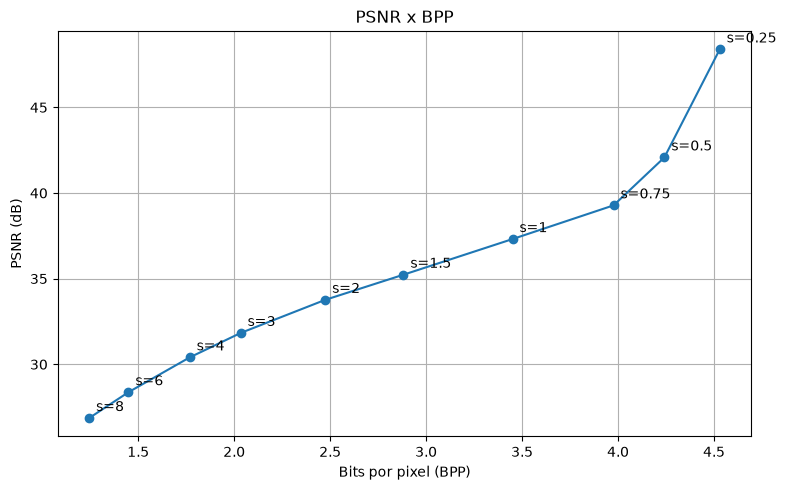

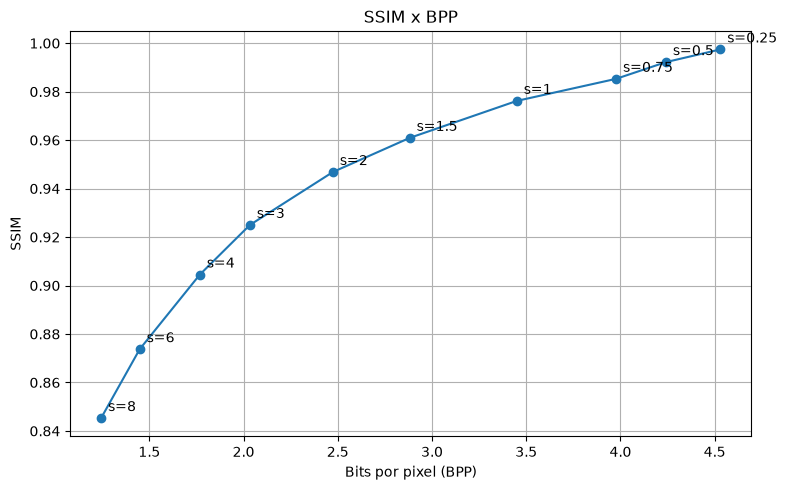

In [9]:
# 7. Curva qualidade x compressão

bpp = [r["bpp"] for r in resultados]
psnr = [r["PSNR"] for r in resultados]
ssim = [r["SSIM"] for r in resultados]

# 7.1 PSNR x BPP
plt.figure(figsize=(8, 5))
plt.plot(bpp, psnr, marker="o")

for r in resultados:
    plt.annotate(
        f"s={r['s']}",
        (r["bpp"], r["PSNR"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Bits por pixel (BPP)")
plt.ylabel("PSNR (dB)")
plt.title("PSNR x BPP")
plt.grid(True)
plt.tight_layout()
plt.show()

# 7.2 SSIM x BPP
plt.figure(figsize=(8, 5))
plt.plot(bpp, ssim, marker="o")

for r in resultados:
    plt.annotate(
        f"s={r['s']}",
        (r["bpp"], r["SSIM"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Bits por pixel (BPP)")
plt.ylabel("SSIM")
plt.title("SSIM x BPP")
plt.grid(True)
plt.tight_layout()
plt.show()
